# Case Study 1: Robinhood Traders and the Case of GameStop

MATH 60231, Financial Econometrics, Fall 2026, individual

## 0. Setup

In [23]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats as st
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.graphics.tsaplots import plot_pacf
import statsmodels.api as sm

DATA_DIR = Path("Data")
RH_PATH = DATA_DIR / "RH_data (1).csv"
STOCK_PATH = DATA_DIR / "stock_data (1).csv"
GME_PATH = DATA_DIR / "gme_yahoo.csv"

### Table formatting

Source used for Table Formatting: [MatPlotLib - Table Demo](https://matplotlib.org/stable/gallery/misc/table_demo.html)

In [24]:
# Table formatting template (Sourced from MatPlotLib, linked above)
os.makedirs("Output", exist_ok=True)                       # every table and figure is also saved as a PNG in Output/

def save_output(fig, label):
    """Save a figure as a PNG in Output/, with a file name built from its label."""
    # File name built from the label: "Table 2.4 – AR models ..." -> Output/Table_2.4_AR_models_....png
    name = re.sub(r"[^A-Za-z0-9.]+", "_", label).strip("_.")[:90]
    fig.savefig(f"Output/{name}.png", dpi=200, bbox_inches="tight")

def table_figure(df, title, row_labels=None, decimals=6, col_colors=None, figsize=(12, 2.2)):
    """Draw a DataFrame as a matplotlib table, save it to Output/ and show it.

    row_labels: labels for the rows (default: the DataFrame index).
    decimals: number of decimals shown for every value; missing values show as "–".
    col_colors: background colour of each column header.
    figsize: figure size in inches (width, height).
    """
    cell_text = [[f"{x:,.{decimals}f}" if pd.notna(x) else "–" for x in row] for row in df.values]   # "–" for empty cells
    row_labels = list(df.index.astype(str)) if row_labels is None else list(row_labels)

    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")
    table = ax.table(cellText=cell_text,
                     rowLabels=row_labels,
                     colLabels=list(df.columns),
                     colColours=col_colors,
                     loc="center",
                     cellLoc="center",
                     rowLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.4)
    ax.set_title(title, pad=20)
    plt.tight_layout()
    save_output(fig, title)                                 # save to Output/ before displaying
    plt.show()

## 1. Load and clean the data

**Assumptions: loading and cleaning**

- Dates in both files look like `01jan2019` and are parsed with the format `%d%b%Y`. Non-numeric CRSP codes in `DlyPrc`, `DlyRet`, `DlyVol` and `vwretd` become NaN.
- Exact duplicate rows in `stock_data` (19 rows) are dropped.
- TAP and STZ have two share classes under one ticker. Each day the row with the higher `DlyVol` (the main, liquid class) is kept, assuming RH users hold the main class.
- Rows with no `DlyRet` (251 rows: mostly a stock's first day, plus long gaps for WORX, LK and MBRX) are dropped, not set to 0. A missing return is unknown, not 0%.
- RH data covers 575 calendar days (weekends included); stock data covers 408 trading days. Holdings on non-trading days carry no return, so the sample is the 408 trading days.
- 57 RH tickers (about 2% of holdings) have no return data. They are handled in T1 (c).

In [25]:
# Load the 2 CSV files
rh = pd.read_csv(RH_PATH)
rh["date"] = pd.to_datetime(rh["date"], format="%d%b%Y")

stock = pd.read_csv(STOCK_PATH)
# Date formatting
stock["DlyCalDt"] = pd.to_datetime(stock["DlyCalDt"], format="%d%b%Y")
# Convert numeric columns to numeric type, converting errors to NaN
for col in ["DlyPrc", "DlyRet", "DlyVol", "vwretd"]:
    stock[col] = pd.to_numeric(stock[col], errors="coerce")

# Check for missing values and duplicates
print(rh.isna().sum(), stock.isna().sum(), sep="\n\n")
print("Duplicates:", rh.duplicated(["date", "tic"]).sum(), stock.duplicated(["DlyCalDt", "Ticker"]).sum())
print("RH tickers with no return data:", len(set(rh["tic"]) - set(stock["Ticker"])))

# Drop exact copies
stock = stock.drop_duplicates()

# Main share classes kept, secondary share classes dropped
stock = (stock.sort_values("DlyVol", ascending=False)
              .drop_duplicates(subset=["DlyCalDt", "Ticker"], keep="first")
              .sort_values(["DlyCalDt", "Ticker"])
              .reset_index(drop=True))

print("Duplicates left:", stock.duplicated(["DlyCalDt", "Ticker"]).sum())   # if all cleaned, should be 0

# Missing return as "unknown"
n_before = len(stock)
stock = stock.dropna(subset=["DlyRet"])

print("Rows dropped for missing DlyRet:", n_before - len(stock))


# Coverage
print("RH dates:   ", rh["date"].min().date(), "to", rh["date"].max().date(), "|", rh["date"].nunique(), "days |", rh["tic"].nunique(), "tickers")
print("Stock dates:", stock["DlyCalDt"].min().date(), "to", stock["DlyCalDt"].max().date(), "|", stock["DlyCalDt"].nunique(), "days |", stock["Ticker"].nunique(), "tickers")


date             0
users_holding    0
tic              0
dtype: int64

Ticker        0
DlyCalDt      0
DlyPrc      157
DlyRet      251
DlyVol      157
vwretd        0
dtype: int64
Duplicates: 0 835
RH tickers with no return data: 57
Duplicates left: 0
Rows dropped for missing DlyRet: 251
RH dates:    2019-01-01 to 2020-08-13 | 575 days | 1445 tickers
Stock dates: 2019-01-02 to 2020-08-13 | 408 days | 1388 tickers


# Technical questions

## T1. The RH representative portfolio vs the market (CRSP VW)

### T1 (a)–(b): RH holdings data and the representative investor

In [26]:
# Pivot RH data to have dates as rows and tickers as columns, with values being the number of users holding each stock
holdings = rh.pivot(index="date", columns="tic", values="users_holding")
print(holdings.shape)
holdings.iloc[:5, :5]

(575, 1445)


tic,AA,AACG,AAL,AAOI,AAPL
date,,,,,
2019-01-01,NaN,NaN,175176.0,55824.0,5204232.0
2019-01-02,NaN,NaN,175245.0,55821.0,5215066.0
2019-01-03,NaN,NaN,171524.0,53481.0,5127936.0
2019-01-04,NaN,NaN,185240.0,55793.0,5509436.0
2019-01-05,NaN,NaN,182616.0,55824.0,5538970.0


### T1 (c): Portfolio weights

**Assumptions: portfolio construction**

- `users_holding` counts accounts, not shares or dollars, so the weights are popularity weights: a user with \$10 and one with \$10,000 count the same.
- Gaps in the RH data (24–29 Jan 2019, 7–15 Jan 2020, and 3 Mar 2019): on the 11 trading days affected, the weights carry forward the last recorded holdings (up to 9 days old), assuming holdings change slowly.
- The first trading day (2019-01-02) uses the 2019-01-01 holdings, so no day is lost.
- The portfolio rebalances daily to these weights, with no trading costs or taxes.

In [27]:
# Returns as the same kind of table as RH
returns = stock.pivot(index="DlyCalDt", columns="Ticker", values="DlyRet")

# Holdings recorded on day d are known from day d+1: shift the dates by +1 day,
# then for each trading day take the most recent holdings available (ffill)
h_prev = holdings.copy()
h_prev.index = h_prev.index + pd.Timedelta(days=1)
h_lag = h_prev.reindex(returns.index, method="ffill").reindex(columns=returns.columns)

# keep only the stocks that have a return that day, then re-normalize
h_lag = h_lag.where(returns.notna())
weights = h_lag.div(h_lag.sum(axis=1), axis=0)

# weights Check 
print(weights.sum(axis=1).describe())


count    4.080000e+02
mean     1.000000e+00
std      7.240802e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64


### T1 (d): Portfolio returns

In [28]:
# Compute the RH portfolio return as the weighted sum of returns
rh_ret = (weights * returns).sum(axis=1, min_count=1)
rh_ret.name = "RH"
rh_ret.describe()


count    408.000000
mean       0.001392
std        0.022226
min       -0.119149
25%       -0.006674
50%        0.001635
75%        0.010582
max        0.103924
Name: RH, dtype: float64

### T1 (e): Market benchmark returns (CRSP VW)

In [29]:
# Benchmark: CRSP value-weighted market return (vwretd), one value per trading day
vw = stock.groupby("DlyCalDt")["vwretd"].first().rename("CRSP VW")

# Align the benchmark on the RH portfolio dates
bench = pd.concat([rh_ret, vw], axis=1, sort=True).loc[rh_ret.index]

print(bench.isna().sum())
print(bench.corr().round(3))

RH         0
CRSP VW    0
dtype: int64
            RH  CRSP VW
RH       1.000    0.881
CRSP VW  0.881    1.000


### T1 (f): Summary statistics and graphs

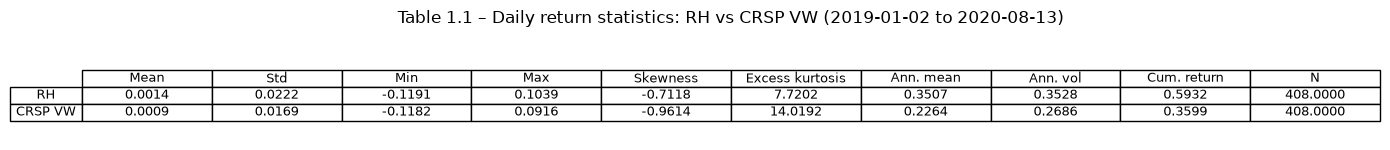

,Mean,Std,Min,Max,Skewness,Excess kurtosis,Ann. mean,Ann. vol,Cum. return,N
RH,0.0014,0.0222,-0.1191,0.1039,-0.7118,7.7202,0.3507,0.3528,0.5932,408
CRSP VW,0.0009,0.0169,-0.1182,0.0916,-0.9614,14.0192,0.2264,0.2686,0.3599,408


In [30]:
# Summary statistics of RH portfolio vs benchmark
stats = pd.DataFrame({
    "Mean":            bench.mean(),
    "Std":             bench.std(),
    "Min":             bench.min(),
    "Max":             bench.max(),
    "Skewness":        bench.skew(),
    "Excess kurtosis": bench.kurt(),            
    "Ann. mean":       bench.mean() * 252,
    "Ann. vol":        bench.std() * np.sqrt(252),
    "Cum. return":     (1 + bench).prod() - 1,
    "N":               bench.count(),
})

table_figure(stats, "Table 1.1 – Daily return statistics: RH vs CRSP VW (2019-01-02 to 2020-08-13)",
             decimals=4, figsize=(14, 1.6))
stats.round(4)

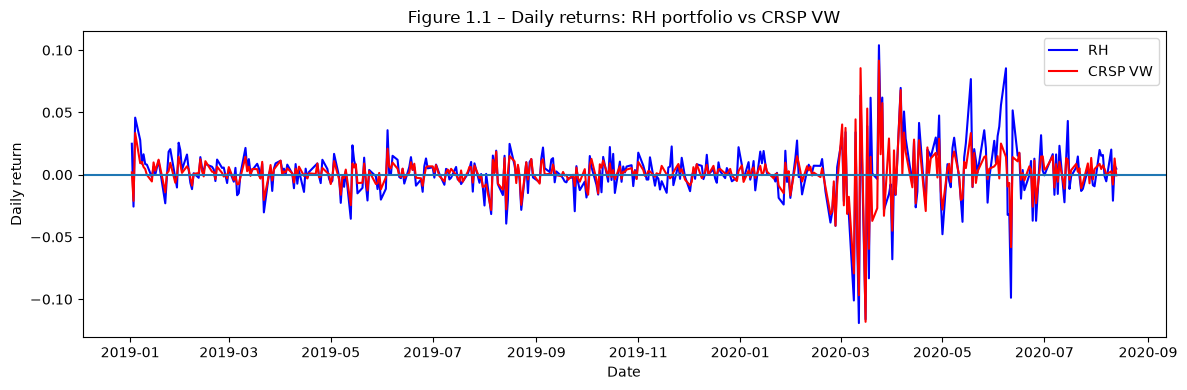

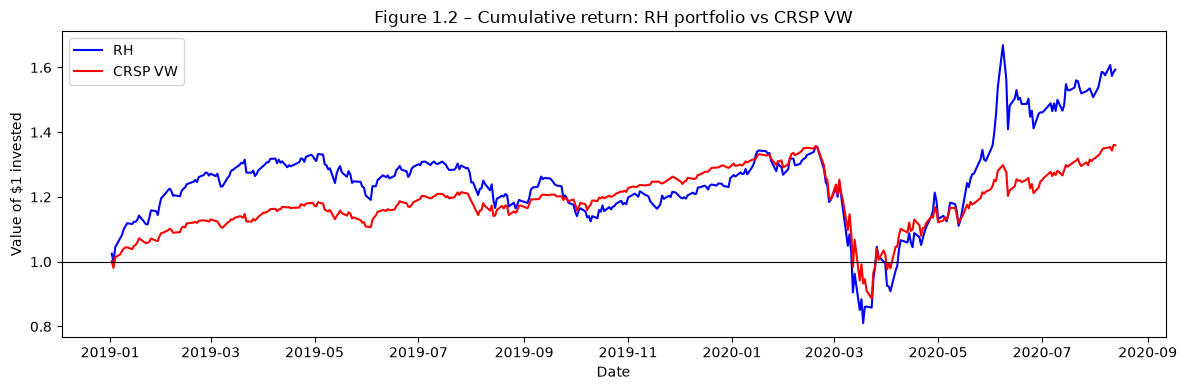

In [31]:
COLORS = {"RH": "blue", "CRSP VW": "red"}

# Graph daily returns over time
fig, ax = plt.subplots(figsize=(12, 4))
for col in bench.columns:
    ax.plot(bench.index, bench[col], color=COLORS[col], label=col)
ax.axhline(0)
ax.set_title("Figure 1.1 – Daily returns: RH portfolio vs CRSP VW")
ax.set_xlabel("Date")
ax.set_ylabel("Daily return")
ax.legend()
plt.tight_layout()
save_output(fig, "Figure 1.1 – Daily returns RH vs CRSP VW")
plt.show()

# Cumulative return
growth = (1 + bench).cumprod()

# Graph cumulative return over time
fig, ax = plt.subplots(figsize=(12, 4))
for col in growth.columns:
    ax.plot(growth.index, growth[col], color=COLORS[col], label=col)
ax.axhline(1, color="black", linewidth=0.8)
ax.set_title("Figure 1.2 – Cumulative return: RH portfolio vs CRSP VW")
ax.set_xlabel("Date")
ax.set_ylabel("Value of $1 invested")
ax.legend()
plt.tight_layout()
save_output(fig, "Figure 1.2 – Cumulative return: RH portfolio vs CRSP VW")
plt.show()

## T2. Risk measures: VaR and expected shortfall

In [32]:
def var_es(r, alpha, method="empirical"):
    """VaR and ES of a return series at level alpha, reported as positive losses."""
    
    
    r = np.asarray(r)
    r = r[~np.isnan(r)]

    # Testing the empirical method
    if method == "empirical":
        q = np.quantile(r, alpha)                 # Quantile of the returns
        var = -q
        es = -r[r <= q].mean()                    # Expected shortfall is computed as the average of the returns at or below the quantile
    
    # Testing the parametric method (For comparison)
    elif method == "parametric":
        mu, sigma = r.mean(), r.std(ddof=1)
        z = st.norm.ppf(alpha)
        var = -(mu + sigma * z)
        es = -(mu - sigma * st.norm.pdf(z) / alpha)
    else:
        raise ValueError("method must be 'empirical' or 'parametric'")

    return var, es

### T2 (a)–(b): Apply to the RH portfolio and the market (CRSP VW)

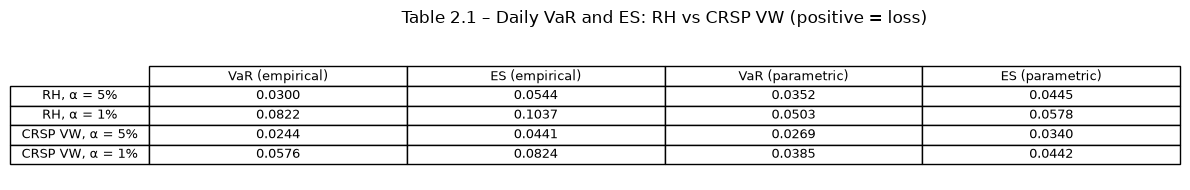

VaR (empirical)  ES (empirical)  VaR (parametric)  \
Series  alpha                                                      
RH      0.05            0.0300          0.0544            0.0352   
        0.01            0.0822          0.1037            0.0503   
CRSP VW 0.05            0.0244          0.0441            0.0269   
        0.01            0.0576          0.0824            0.0385   

               ES (parametric)  
Series  alpha                   
RH      0.05            0.0445  
        0.01            0.0578  
CRSP VW 0.05            0.0340  
        0.01            0.0442

In [33]:
rows = []
for series in bench.columns:                     
    for alpha in [0.05, 0.01]:
        row = {"Series": series, "alpha": alpha}
        for method in ["empirical", "parametric"]:
            var, es = var_es(bench[series], alpha, method)
            row[f"VaR ({method})"] = var
            row[f"ES ({method})"] = es
        rows.append(row)

risk = pd.DataFrame(rows).set_index(["Series", "alpha"])

table_figure(risk, "Table 2.1 – Daily VaR and ES: RH vs CRSP VW (positive = loss)",
             row_labels=[f"{s}, α = {a:.0%}" for s, a in risk.index],
             decimals=4, figsize=(12, 2))
risk.round(4)


## T3. GameStop: rolling AR(p) forecast

### T3 data: GME prices and returns

In [34]:
# GME data from Yahoo Finance
gme_p = pd.read_csv(GME_PATH, index_col=0, parse_dates=True).iloc[:, 0]
gme_ret = gme_p.pct_change().dropna().rename("GME")
print("GME:", gme_ret.index.min().date(), "to", gme_ret.index.max().date(), "|", len(gme_ret), "days")

GME: 2019-01-03 to 2021-02-26 | 542 days


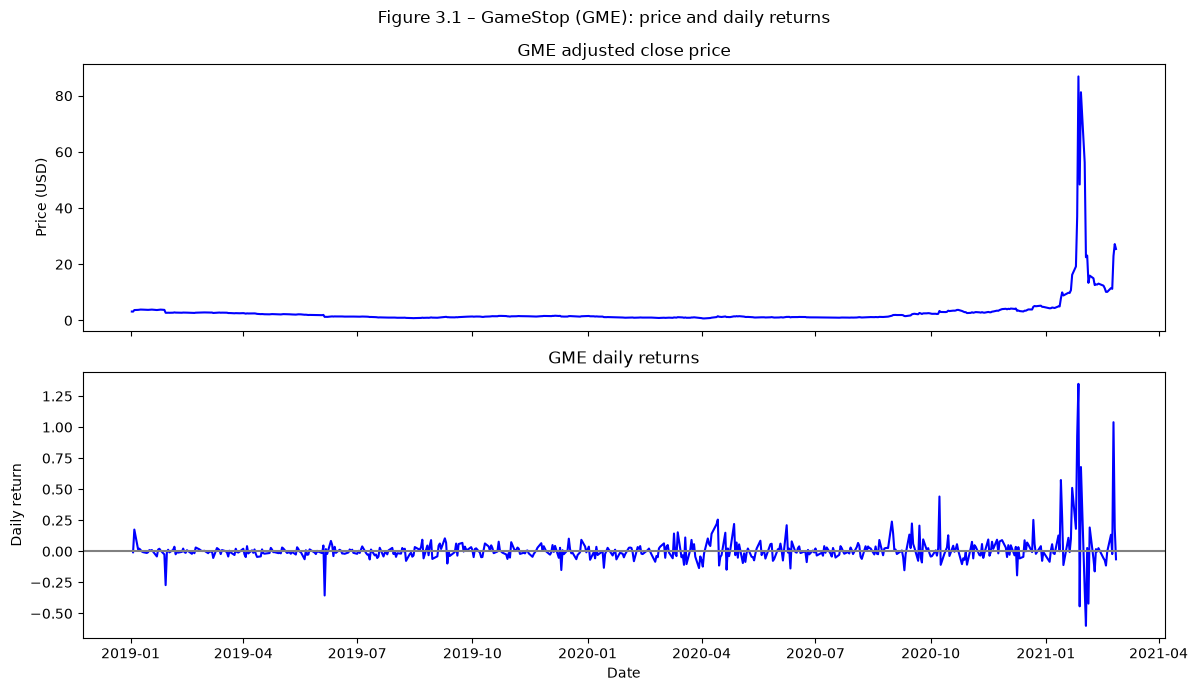

In [35]:
# GME price and daily returns, Jan 2019 to Feb 2021
# Setup plots:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Price
axes[0].plot(gme_p.index, gme_p, color="blue")
axes[0].set_title("GME adjusted close price")
axes[0].set_ylabel("Price (USD)")

# Daily returns
axes[1].plot(gme_ret.index, gme_ret, color="blue")
axes[1].axhline(0, color="gray")
axes[1].set_title("GME daily returns")
axes[1].set_ylabel("Daily return")
axes[1].set_xlabel("Date")

fig.suptitle("Figure 3.1 – GameStop (GME): price and daily returns")
plt.tight_layout()
save_output(fig, "Figure 3.1 – GME price and returns")
plt.show()


In [36]:
# Do the Yahoo GME returns match the CRSP GME returns on the overlapping dates?
crsp_gme = stock.loc[stock["Ticker"] == "GME"].set_index("DlyCalDt")["DlyRet"]
both = pd.concat([gme_ret, crsp_gme.rename("CRSP")], axis=1).dropna()

print("Overlapping days:", len(both))
print("Correlation:", round(both.corr().iloc[0, 1], 4))
print("Mean absolute difference:", round((both["GME"] - both["CRSP"]).abs().mean(), 6))


Overlapping days: 407
Correlation: 1.0
Mean absolute difference: 2e-06


C:\Users\natha\AppData\Local\Temp\ipykernel_38300\2989572088.py:3: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  both = pd.concat([gme_ret, crsp_gme.rename("CRSP")], axis=1).dropna()


### T3 (a): Build the rolling forecast

AIC selected lags: None
BIC selected lags: None


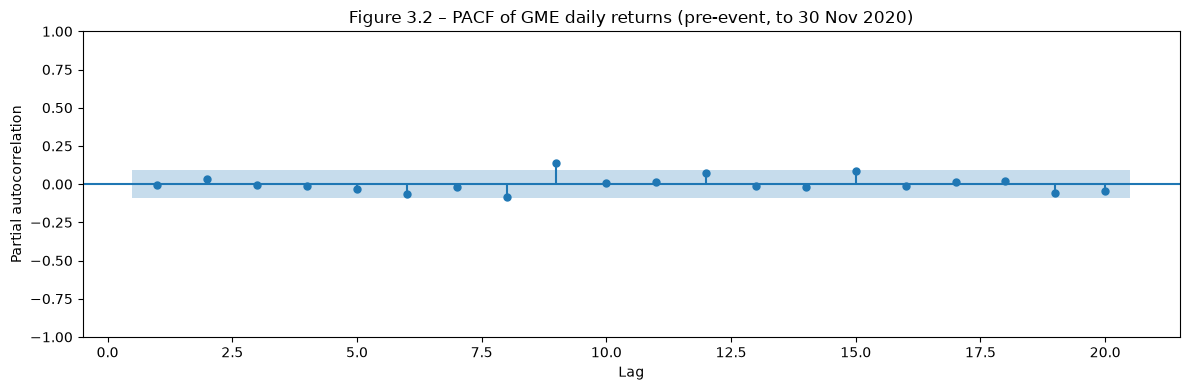

In [37]:
# Select p on pre-event data only (avoiding look-ahead into Jan 2021)
gme_pre = gme_ret.loc[:"2020-11-30"].to_numpy()


for ic in ["aic", "bic"]:       #https://www.statsmodels.org/stable/generated/statsmodels.tsa.ar_model.ar_select_order.html
    sel_p = ar_select_order(gme_pre, maxlag=10, ic=ic) # 10 lags seems reasonable (2 trading weeks)
    print(ic.upper(), "selected lags:", sel_p.ar_lags)

# Plot PACF of pre-event GME returns
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(gme_pre, lags=20, ax=ax, zero=False)            # https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_pacf.html
ax.set_title("Figure 3.2 – PACF of GME daily returns (pre-event, to 30 Nov 2020)")
ax.set_xlabel("Lag")
ax.set_ylabel("Partial autocorrelation")
plt.tight_layout()
save_output(fig, "Figure 3.2 – PACF GME pre-event")
plt.show()


In [38]:
P = 1
W = 250        # rolling window length (about 1 trading year)

y = gme_ret.to_numpy()
fc_list = []
for t in range(W, len(y)):                       # https://www.statsmodels.org/stable/generated/statsmodels.tsa.ar_model.AutoReg.html
    fit_res = AutoReg(y[t - W:t], lags=P).fit()     # fit on days t-W to t-1
    fc_list.append(fit_res.forecast(1)[0])                          # forecast day t

forecast = pd.Series(fc_list, index=gme_ret.index[W:], name="AR forecast")
actual = gme_ret.loc[forecast.index].rename("Actual")
error = (actual - forecast).rename("Error")

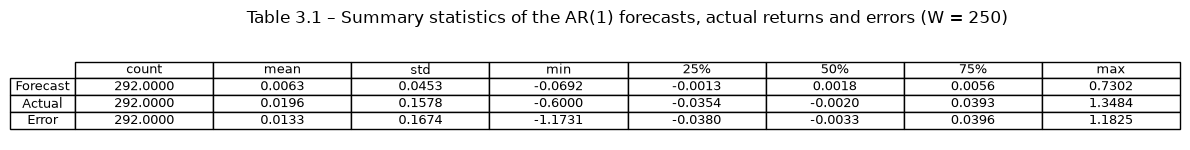

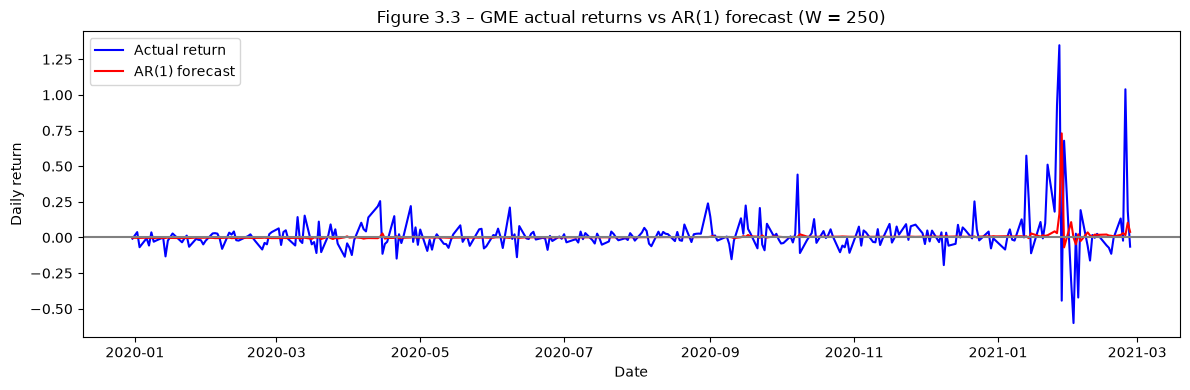

In [39]:
fc_stats = pd.DataFrame({"Forecast": forecast, "Actual": actual, "Error": error}).describe().T

# Call table_figure
table_figure(fc_stats, f"Table 3.1 – Summary statistics of the AR({P}) forecasts, actual returns and errors (W = {W})",
             decimals=4, figsize=(12, 1.6))

# Build plot of actual vs forecast
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(actual.index, actual, color="blue", label="Actual return")
ax.plot(forecast.index, forecast, color="red", label=f"AR({P}) forecast")
ax.axhline(0, color="gray")
ax.set_title(f"Figure 3.3 – GME actual returns vs AR({P}) forecast (W = {W})")
ax.set_xlabel("Date")
ax.set_ylabel("Daily return")
ax.legend()
plt.tight_layout()
save_output(fig, "Figure 3.3 – GME actual vs AR forecast")
plt.show()


### T3 (b): Forecast accuracy

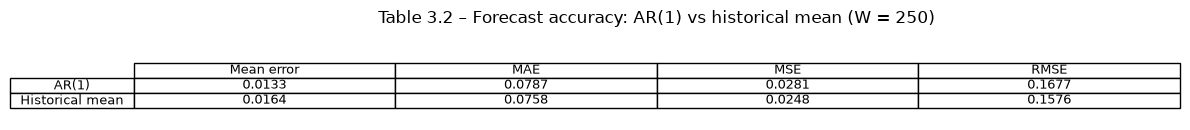

R2_OS vs historical mean: -0.1316


In [40]:
# Historical mean of the same 250-day rolling window
hist_mean = gme_ret.rolling(W).mean().shift(1).loc[forecast.index]
e_ar = actual - forecast
e_mean = actual - hist_mean

# The four stats
rows = {}
for name, e in {f"AR({P})": e_ar, "Historical mean": e_mean}.items():
    rows[name] = {"Mean error": e.mean(),
                  "MAE": e.abs().mean(),
                  "MSE": (e ** 2).mean(),
                  "RMSE": np.sqrt((e ** 2).mean())}
accuracy = pd.DataFrame(rows).T

r2_os = 1 - accuracy.loc[f"AR({P})", "MSE"] / accuracy.loc["Historical mean", "MSE"]

# Call table_figure
table_figure(accuracy, f"Table 3.2 – Forecast accuracy: AR({P}) vs historical mean (W = {W})",
             decimals=4, figsize=(12, 1.4))

# showing the R2_OS value
print(f"R2_OS vs historical mean: {r2_os:.4f}")


d_bar = 0.0033  |  95% interval: [-0.0049, 0.0115]
DM = 0.781  |  MDM = 0.779  |  p (two-sided, t(291)) = 0.436


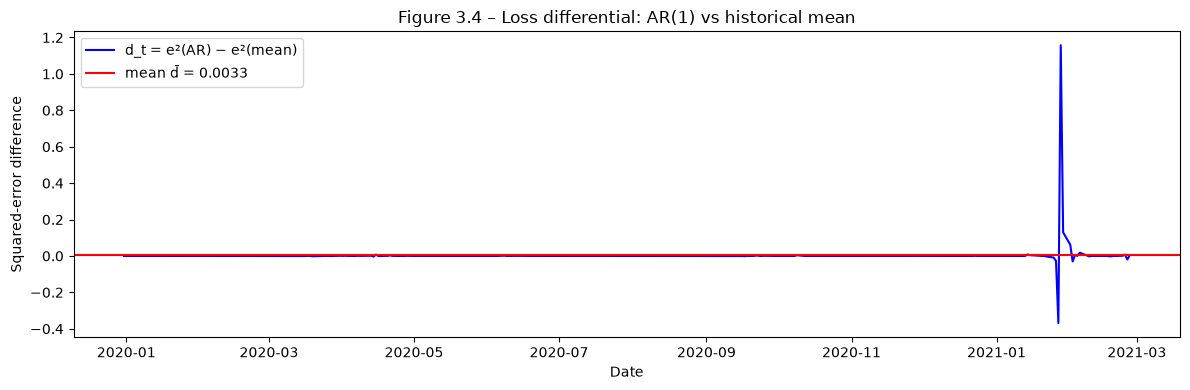

In [41]:
# Variables for the DM test
h = 1
d = (e_ar ** 2 - e_mean ** 2).to_numpy()
n_fc = len(d)

# DM test
dm_fit = sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": h - 1})
dm = dm_fit.tvalues[0]
mdm = dm * np.sqrt((n_fc + 1 - 2 * h + h * (h - 1) / n_fc) / n_fc)     # HLN small-sample factor
p_value = 2 * st.t.sf(abs(mdm), n_fc - 1)

# DM test results
d_bar, se_d = dm_fit.params[0], dm_fit.bse[0]
print(f"d_bar = {d_bar:.4f}  |  95% interval: [{d_bar - 1.96 * se_d:.4f}, {d_bar + 1.96 * se_d:.4f}]")
print(f"DM = {dm:.3f}  |  MDM = {mdm:.3f}  |  p (two-sided, t({n_fc - 1})) = {p_value:.3f}")

# Plot the loss differential
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(forecast.index, d, color="blue", label="d_t = e²(AR) − e²(mean)")
ax.axhline(d_bar, color="red", label=f"mean d̄ = {d_bar:.4f}")
ax.set_title(f"Figure 3.4 – Loss differential: AR({P}) vs historical mean")
ax.set_xlabel("Date")
ax.set_ylabel("Squared-error difference")
ax.legend()
plt.tight_layout()
save_output(fig, "Figure 3.4 – Loss differential AR vs mean")
plt.show()


### T3 (c): Accuracy during the GameStop incident

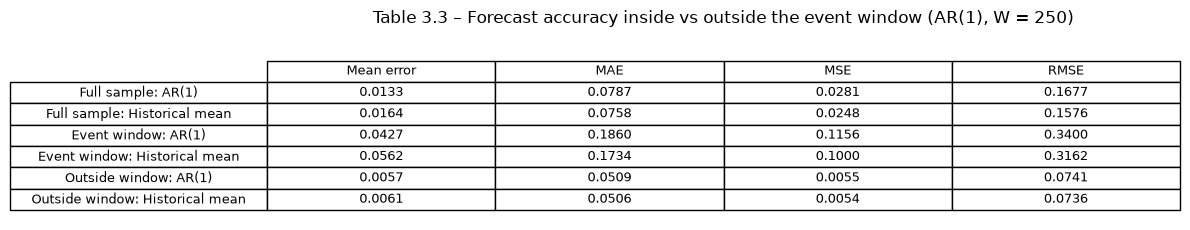

Full sample: N = 292 | R2_OS = -0.1316
Event window: N = 60 | R2_OS = -0.1562
Outside window: N = 232 | R2_OS = -0.0141


In [42]:
# Event window: 1 Dec 2020 to the end of the data (26 Feb 2021)
in_event = forecast.index >= "2020-12-01"
samples = {"Full sample": forecast.index,
           "Event window": forecast.index[in_event],
           "Outside window": forecast.index[~in_event]}

# Same four stats as Table 3.2, for each sample and each model
rows = {}
for sample, idx in samples.items():
    for name, e in {f"AR({P})": e_ar, "Historical mean": e_mean}.items():
        e_s = e.loc[idx]
        rows[(sample, name)] = {"Mean error": e_s.mean(),
                                "MAE": e_s.abs().mean(),
                                "MSE": (e_s ** 2).mean(),
                                "RMSE": np.sqrt((e_s ** 2).mean())}
event_acc = pd.DataFrame(rows).T

# Call table_figure
table_figure(event_acc, f"Table 3.3 – Forecast accuracy inside vs outside the event window (AR({P}), W = {W})",
             row_labels=[f"{s}: {m}" for s, m in event_acc.index], decimals=4, figsize=(12, 2.4))

# R2_OS and number of forecasts in each sample
for sample in samples:
    r2 = 1 - event_acc.loc[(sample, f"AR({P})"), "MSE"] / event_acc.loc[(sample, "Historical mean"), "MSE"]
    print(f"{sample}: N = {len(samples[sample])} | R2_OS = {r2:.4f}")


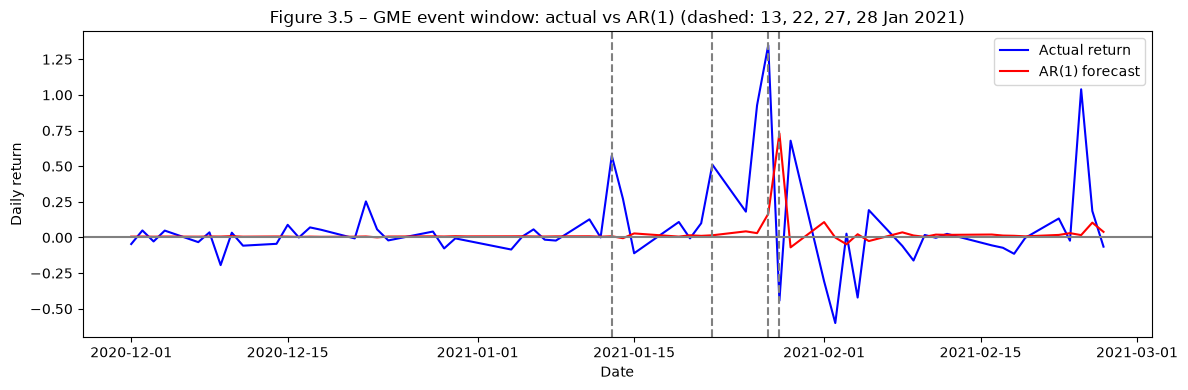

In [43]:
KEY_DATES = ["2021-01-13", "2021-01-22", "2021-01-27", "2021-01-28"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(actual.index[in_event], actual[in_event], color="blue", label="Actual return")
ax.plot(forecast.index[in_event], forecast[in_event], color="red", label=f"AR({P}) forecast")
for day in KEY_DATES:
    ax.axvline(pd.Timestamp(day), color="gray", linestyle="--")
ax.axhline(0, color="gray")
ax.set_title(f"Figure 3.5 – GME event window: actual vs AR({P}) (dashed: 13, 22, 27, 28 Jan 2021)")
ax.set_xlabel("Date")
ax.set_ylabel("Daily return")
ax.legend()
plt.tight_layout()
save_output(fig, "Figure 3.5 – GME event window actual vs AR forecast")
plt.show()


---
# Discussion support

## D2. Risk–reward measure

### D2 (a)–(c): Sharpe ratio and tail-adjusted ratio

**Assumptions: risk–reward measures**

- Sharpe ratio = mean return / standard deviation, with no risk-free rate, daily and annualized (× √252).
- Tail-adjusted ratio = mean daily return / empirical 5% ES from Table 2.1, because the Sharpe ratio ignores the fat tails seen in Table 1.1.
- Same sample as T1 and T2: 408 trading days, RH vs CRSP VW.

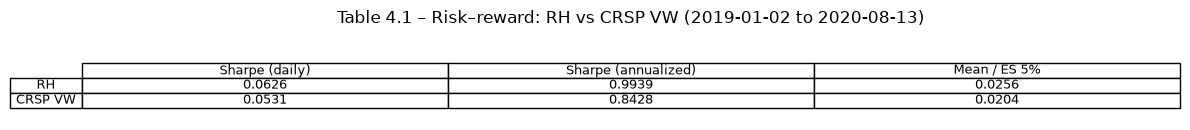

,Sharpe (daily),Sharpe (annualized),Mean / ES 5%
RH,0.0626,0.9939,0.0256
CRSP VW,0.0531,0.8428,0.0204


In [44]:
# Empirical 5% ES of each series, from Table 2.1
es_5 = risk.xs(0.05, level="alpha")["ES (empirical)"]

# Risk-reward measures
reward = pd.DataFrame({
    "Sharpe (daily)":      bench.mean() / bench.std(),
    "Sharpe (annualized)": bench.mean() / bench.std() * np.sqrt(252),
    "Mean / ES 5%":        bench.mean() / es_5,
})

# Call table_figure
table_figure(reward, "Table 4.1 – Risk–reward: RH vs CRSP VW (2019-01-02 to 2020-08-13)",
             decimals=4, figsize=(12, 1.4))
reward.round(4)